## Cell 1: Install Library Ultralytics
Jalankan kode ini untuk memasang package YOLOv8.

In [ ]:
!pip -q install ultralytics

## Cell 2: Import Library & Cek Hardware GPU
Memastikan versi library dan ketersediaan akselerasi GPU.

In [ ]:
import torch
import ultralytics
from ultralytics import YOLO

print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Hubungkan Google Drive

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Cek ZIP

In [ ]:
zip_path = "/content/drive/MyDrive/ComputerVision/Chair Vacancy Detection.v2i.yolov8.zip"

import os

print("File ada:", os.path.exists(zip_path))
print("Path:", zip_path)

Extract ZIP

In [ ]:
import zipfile
import os

extract_path = "/content/chair_dataset_v2"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset berhasil diekstrak.")

Cek struktur hasil extract

In [ ]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 2:
        print(root)

/content/chair_dataset_v2
/content/chair_dataset_v2/train
/content/chair_dataset_v2/train/labels
/content/chair_dataset_v2/train/images
/content/chair_dataset_v2/test
/content/chair_dataset_v2/test/labels
/content/chair_dataset_v2/test/images
/content/chair_dataset_v2/valid
/content/chair_dataset_v2/valid/labels
/content/chair_dataset_v2/valid/images


Bikin yolo_data.yaml

In [ ]:
data_yaml = """
path: /content/chair_dataset_v2
train: train/images
val: valid/images
test: test/images

nc: 2
names:
  0: Occupied-chair
  1: Unoccupied-chair
"""

import os

os.makedirs("/content/chair_dataset_v2", exist_ok=True)

with open("/content/chair_dataset_v2/yolo_data.yaml", "w") as f:
    f.write(data_yaml)

print(data_yaml)


path: /content/chair_dataset_v2
train: train/images
val: valid/images
test: test/images

nc: 2
names:
  0: Occupied-chair
  1: Unoccupied-chair



## Cell 3: Load Pretrained Model YOLOv10
Mengunduh bobot awal yolov8n (nano) untuk proses fine-tuning.

In [ ]:
model = YOLO("yolov10n.pt")

Catatan Dataset & Annotation:

Dataset yang digunakan adalah COCO8. Format koordinat bounding box YOLO disimpan dalam file .txt dengan

struktur:

class_id x_center y_center width height

## Cell 4: Training Model YOLOv10
Melatih model pada dataset coco8.yaml sebanyak maksimal 10 epoch.

In [ ]:
# Cell 4: Training Model YOLOv10n
results = model.train(
    data="/content/chair_dataset_v2/yolo_data.yaml",
    epochs=10,
    imgsz=640,
    batch=8,
    patience=5,
    project="/content/runs",
    name="yolov10n_chair"
)

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/chair_dataset_v2/yolo_data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov10n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov10n_chair-4, nbs=64, nms=None, opset=None, o

Toleransi patience=5 memicu Early Stopping jika nilai evaluasi validation tidak membaik. File bobot terbaik otomatis tersimpan sebagai best.pt.

## Cell 5: Evaluasi / Validasi Model
Mengukur metrik Precision, Recall, dan mAP tanpa memperbarui bobot.

In [ ]:
# Cell 5: Evaluasi / Validasi Model
metrics = model.val(
    data="/content/chair_dataset_v2/yolo_data.yaml",
    imgsz=640,
    batch=8,
    plots=True
)

print(f"Precision   : {metrics.box.mp:.4f}")
print(f"Recall      : {metrics.box.mr:.4f}")
print(f"mAP@50      : {metrics.box.map50:.4f}")
print(f"mAP@50-95   : {metrics.box.map:.4f}")
print(f"mAP@75      : {metrics.box.map75:.4f}")

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10n summary (fused): 100 layers, 2,280,310 parameters, 0 gradients, 6.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2069.3±610.2 MB/s, size: 78.5 KB)
val: Scanning /content/chair_dataset_v2/valid/labels.cache... 351 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 351/351 105.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 9.7it/s 4.5s
                   all        351       2760      0.952      0.979      0.953      0.862
        Occupied-chair        337       1187      0.943      0.972      0.939      0.835
      Unoccupied-chair        339       1573      0.962      0.986      0.966      0.888
Speed: 1.0ms preprocess, 3.6ms inference, 0.0ms loss, 2.7ms postprocess per image
Results saved to /content/runs/detect/val-2
Precision   : 0.9523
Recall      : 0.9792
mAP@50      : 0.9527
mAP@50-95   : 0.8615
m

## Cell 6: Inference pada Gambar Baru
Menguji model dengan mengunduh gambar bus dan menampilkan kotak deteksi (bounding box).

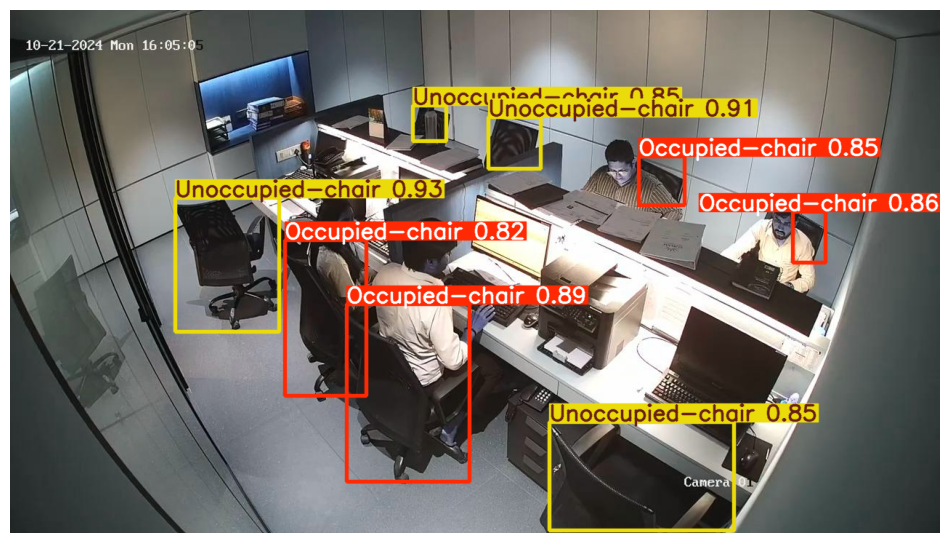

Gambar: /content/chair_dataset_v2/test/images/Video3_mp4-0044_jpg.rf.65d451231b8678570bba686e9f1cc944.jpg
Jumlah objek terdeteksi: 8


In [ ]:
# Cell 6: Inference pada gambar test dataset

import glob
from PIL import Image
import matplotlib.pyplot as plt

test_images = glob.glob("/content/chair_dataset_v2/test/images/*")

image_path = test_images[0]

result = model.predict(
    source=image_path,
    conf=0.25,
    iou=0.45,
    verbose=False
)[0]

plt.figure(figsize=(12, 7))
plt.imshow(result.plot())
plt.axis("off")
plt.show()

print("Gambar:", image_path)
print("Jumlah objek terdeteksi:", len(result.boxes))

## Cell 7: Eksperimen Confidence Threshold
Mengamati variasi jumlah objek terdeteksi saat batas skor keyakinan (confidence) diubah.

In [ ]:
# Cell 7: Eksperimen Confidence Threshold

for t in [0.10, 0.25, 0.50, 0.75]:
    r = model.predict(
        source=image_path,
        conf=t,
        iou=0.45,
        verbose=False
    )[0]

    print(f"Threshold {t:.2f}: {len(r.boxes)} objek terdeteksi")

Threshold 0.10: 8 objek terdeteksi
Threshold 0.25: 8 objek terdeteksi
Threshold 0.50: 8 objek terdeteksi
Threshold 0.75: 8 objek terdeteksi


Evaluasi TEST SET

In [ ]:
# Evaluasi pada TEST SET
test_metrics = model.val(
    data="/content/chair_dataset_v2/yolo_data.yaml",
    split="test",
    imgsz=640,
    batch=8,
    plots=True
)

print(f"Precision   : {test_metrics.box.mp:.4f}")
print(f"Recall      : {test_metrics.box.mr:.4f}")
print(f"mAP@50      : {test_metrics.box.map50:.4f}")
print(f"mAP@50-95   : {test_metrics.box.map:.4f}")
print(f"mAP@75      : {test_metrics.box.map75:.4f}")

Ultralytics 8.4.176 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLOv10n summary (fused): 100 layers, 2,280,310 parameters, 0 gradients, 6.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1388.1±410.1 MB/s, size: 78.6 KB)
val: Scanning /content/chair_dataset_v2/test/labels... 175 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 175/175 1.5Kit/s 0.1s
val: New cache created: /content/chair_dataset_v2/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 7.0it/s 3.1s
                   all        175       1395      0.965      0.973      0.968       0.87
        Occupied-chair        172        637      0.964      0.965      0.968      0.842
      Unoccupied-chair        172        758      0.967       0.98      0.967      0.897
Speed: 1.5ms preprocess, 5.9ms inference, 0.0ms loss, 2.1ms postprocess per image
Results saved to /content/runs/detect/val-4
Precision   : 0.9653
Recall

Coba inference beberapa gambar

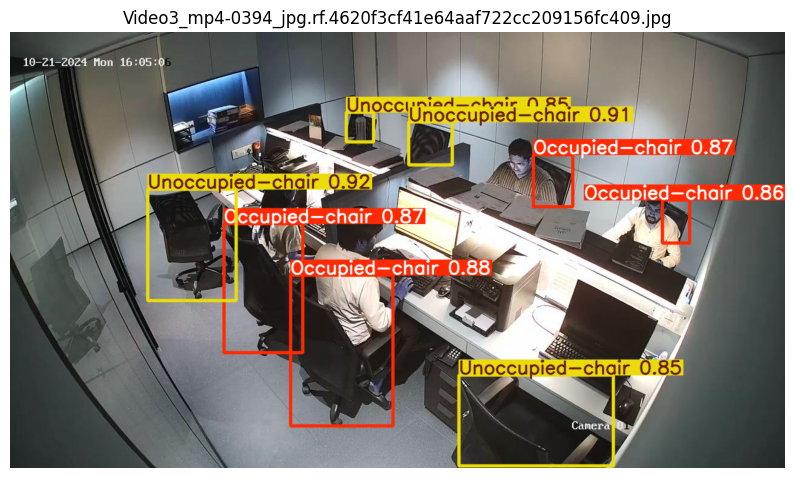

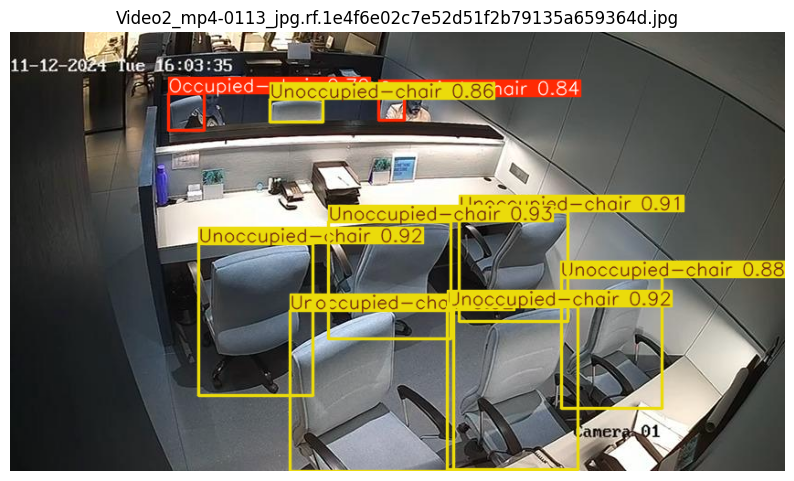

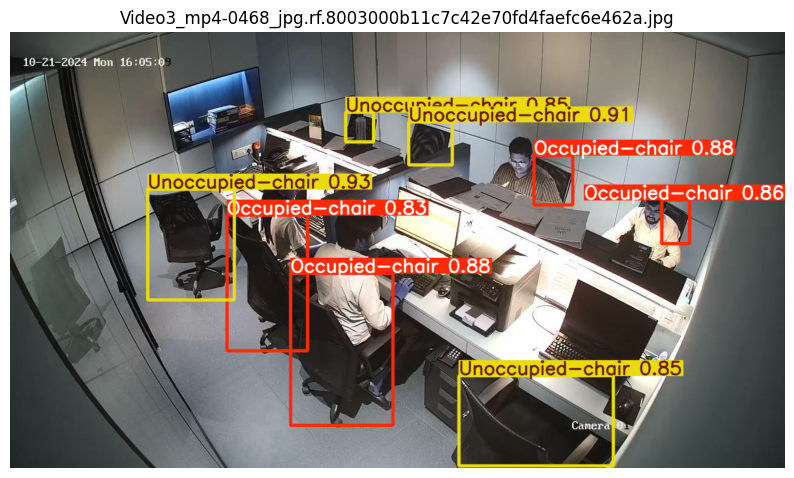

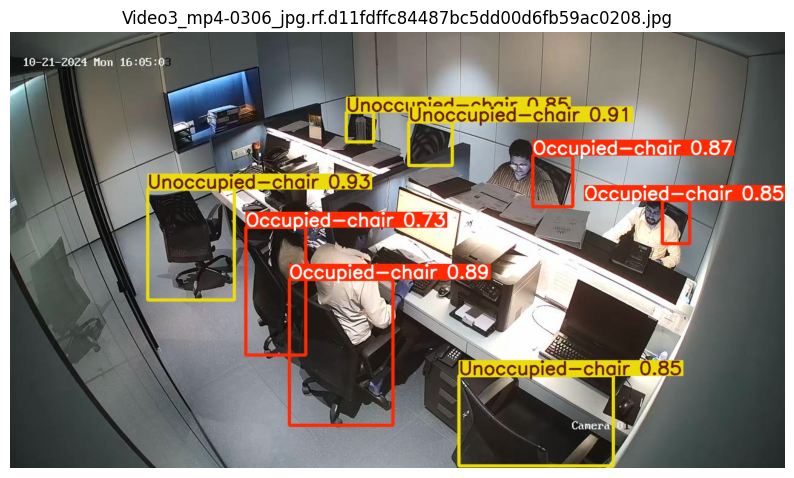

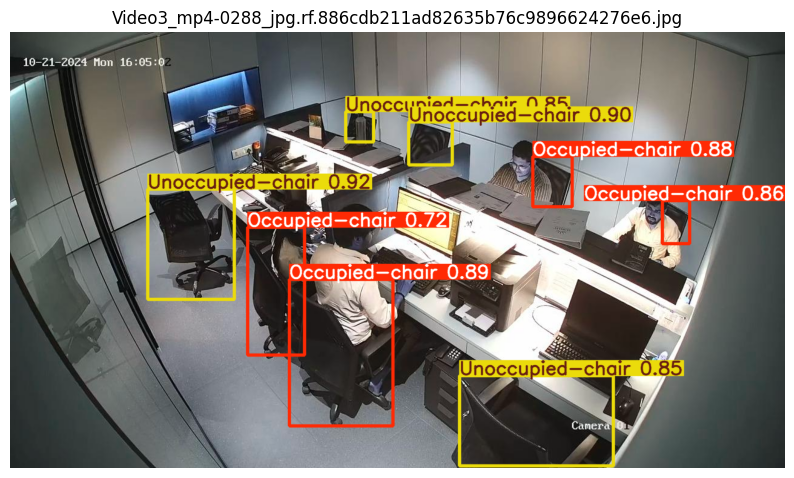

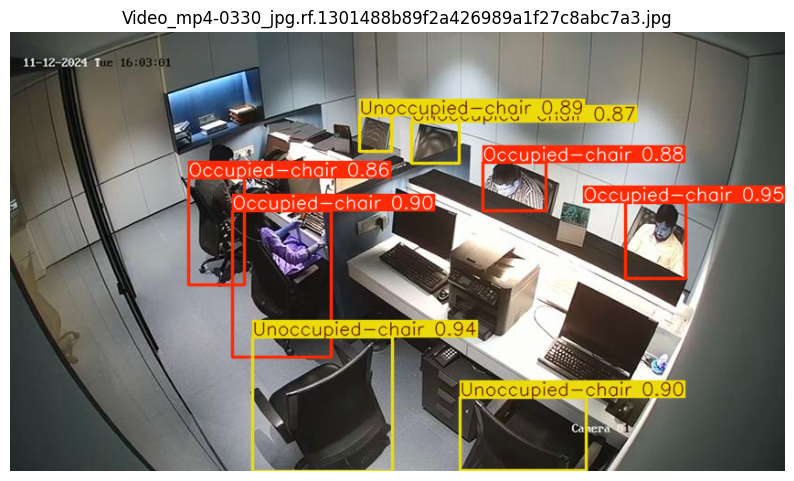

In [ ]:
import random
import glob
import matplotlib.pyplot as plt

test_images = glob.glob("/content/chair_dataset_v2/test/images/*")
sample_images = random.sample(test_images, 6)

for image_path in sample_images:
    result = model.predict(
        source=image_path,
        conf=0.25,
        iou=0.45,
        verbose=False
    )[0]

    plt.figure(figsize=(10, 6))
    plt.imshow(result.plot())
    plt.title(image_path.split("/")[-1])
    plt.axis("off")
    plt.show()

Confusion Matrix

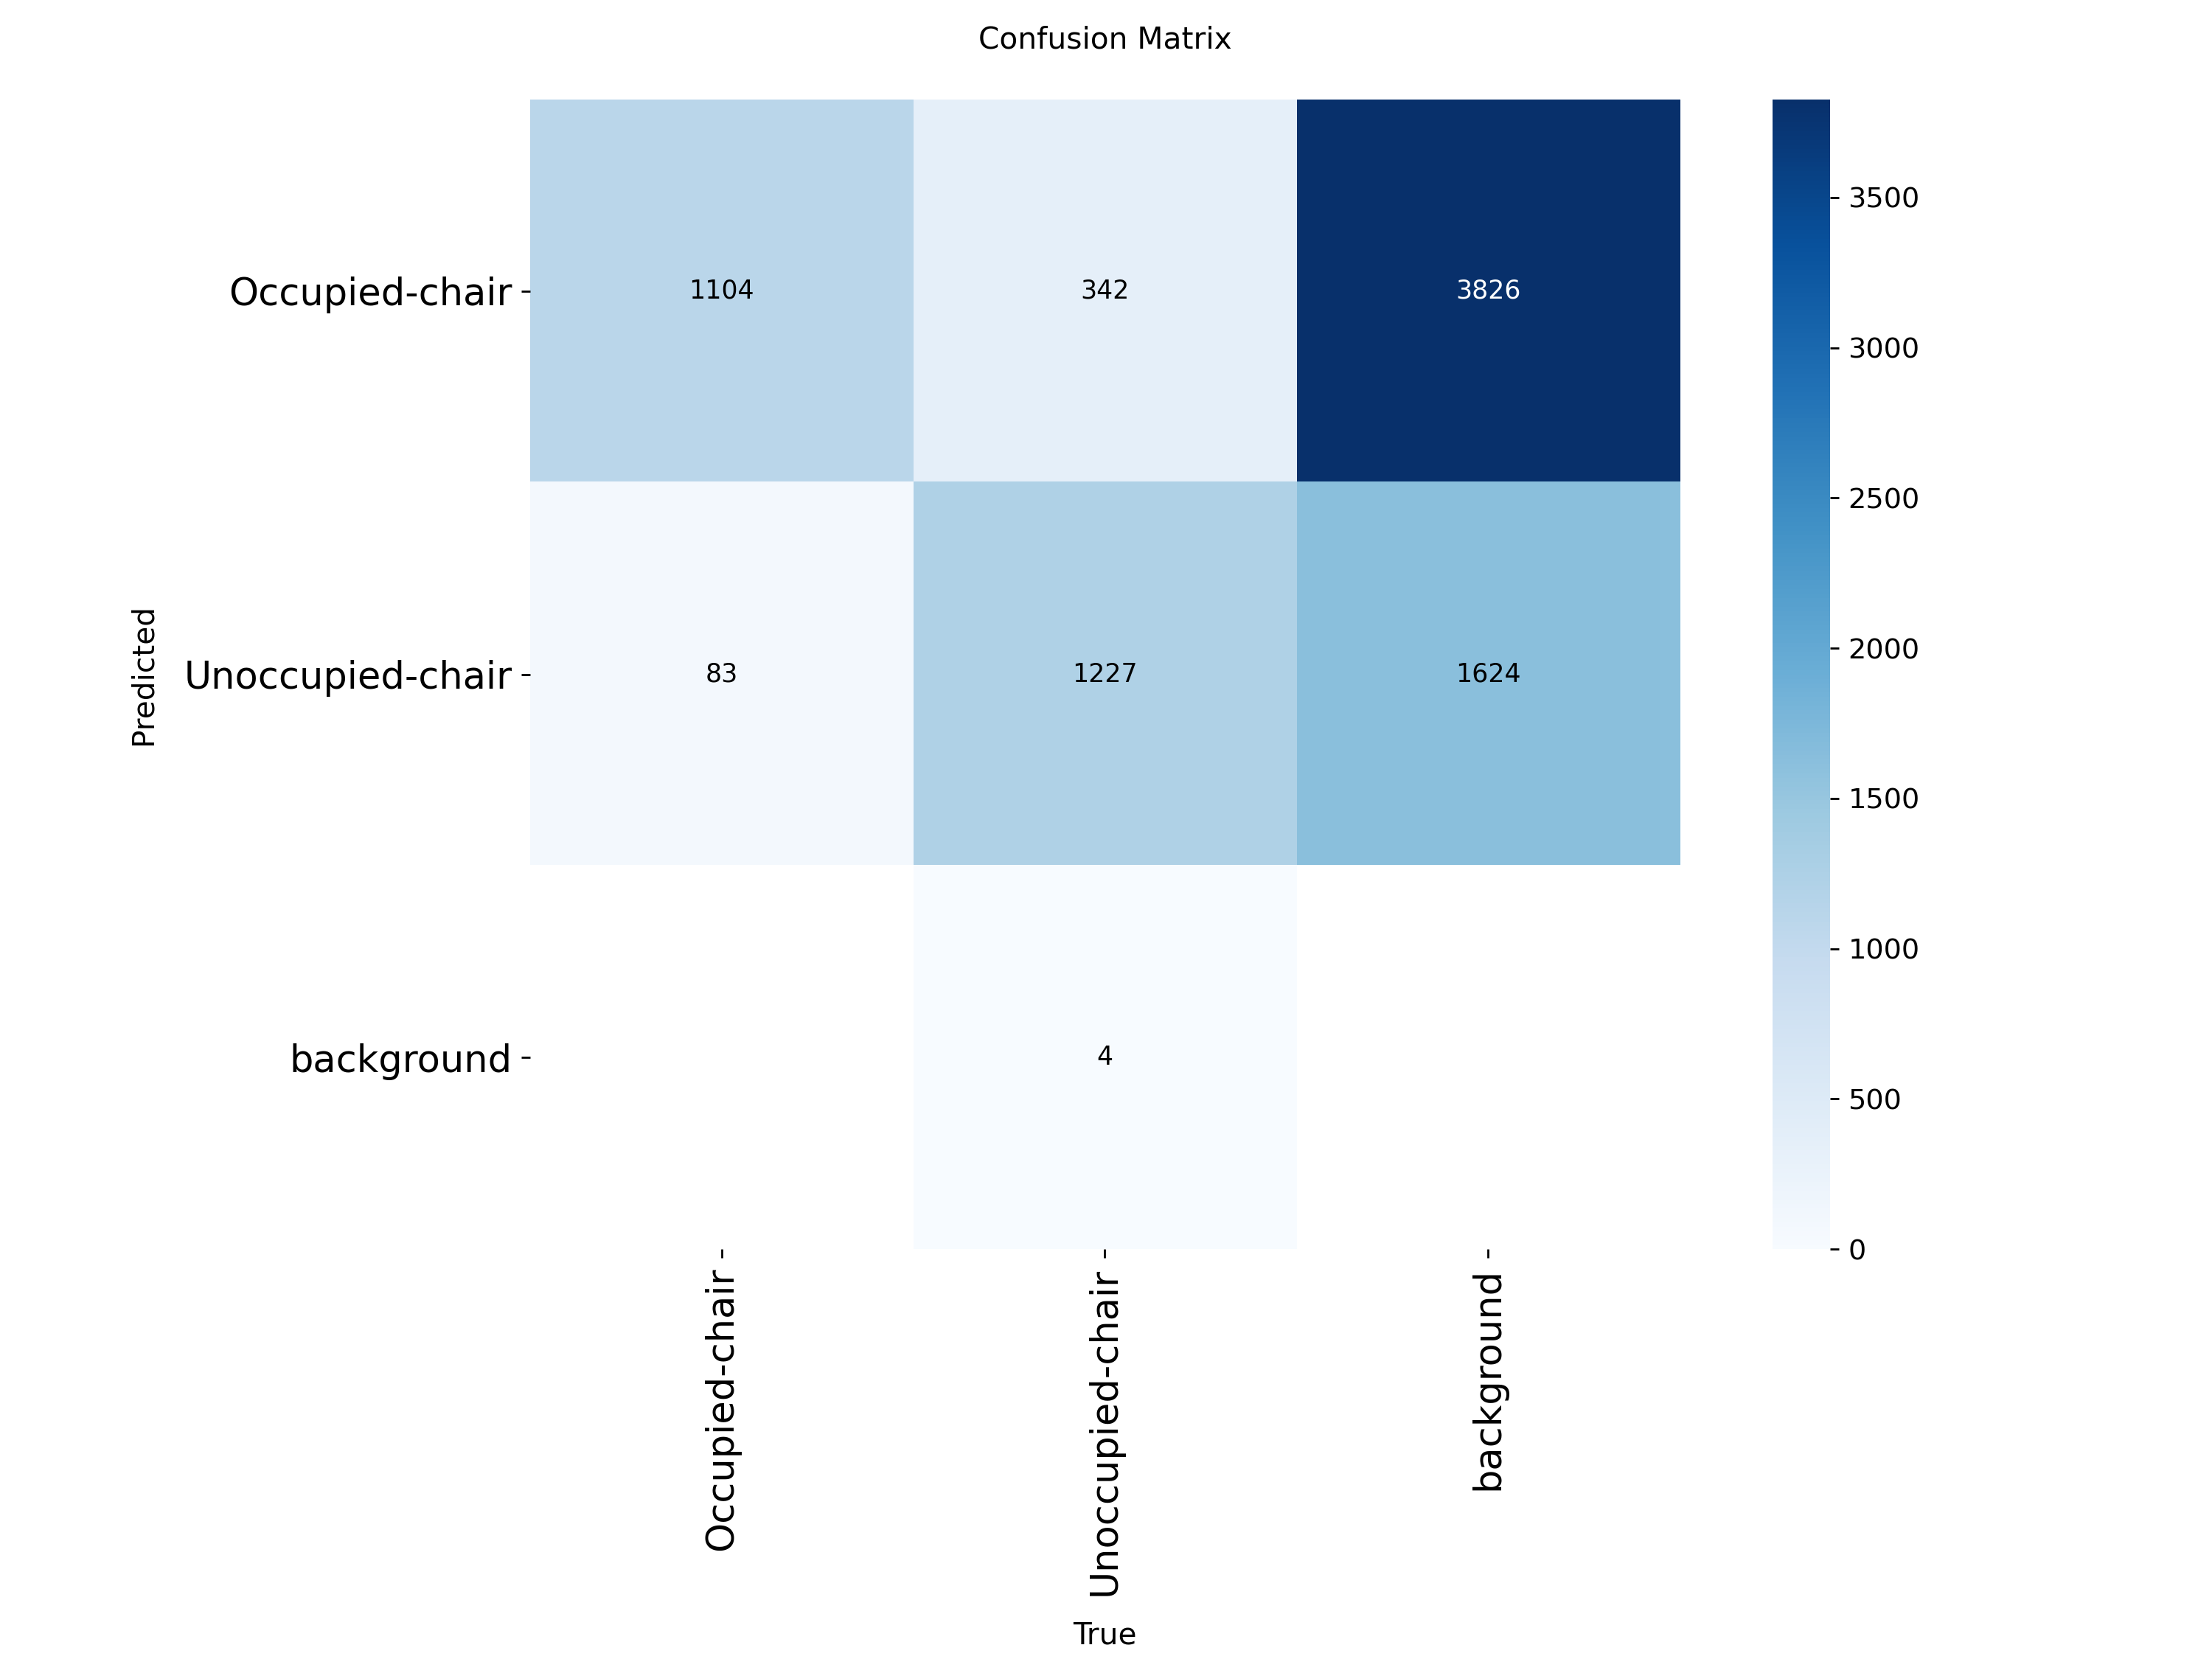

In [ ]:
from IPython.display import display
from PIL import Image
import os

cm_path = "/content/runs/detect/val-2/confusion_matrix.png"

if os.path.exists(cm_path):
    display(Image.open(cm_path))
else:
    print("Confusion matrix tidak ditemukan.")

versi normalized

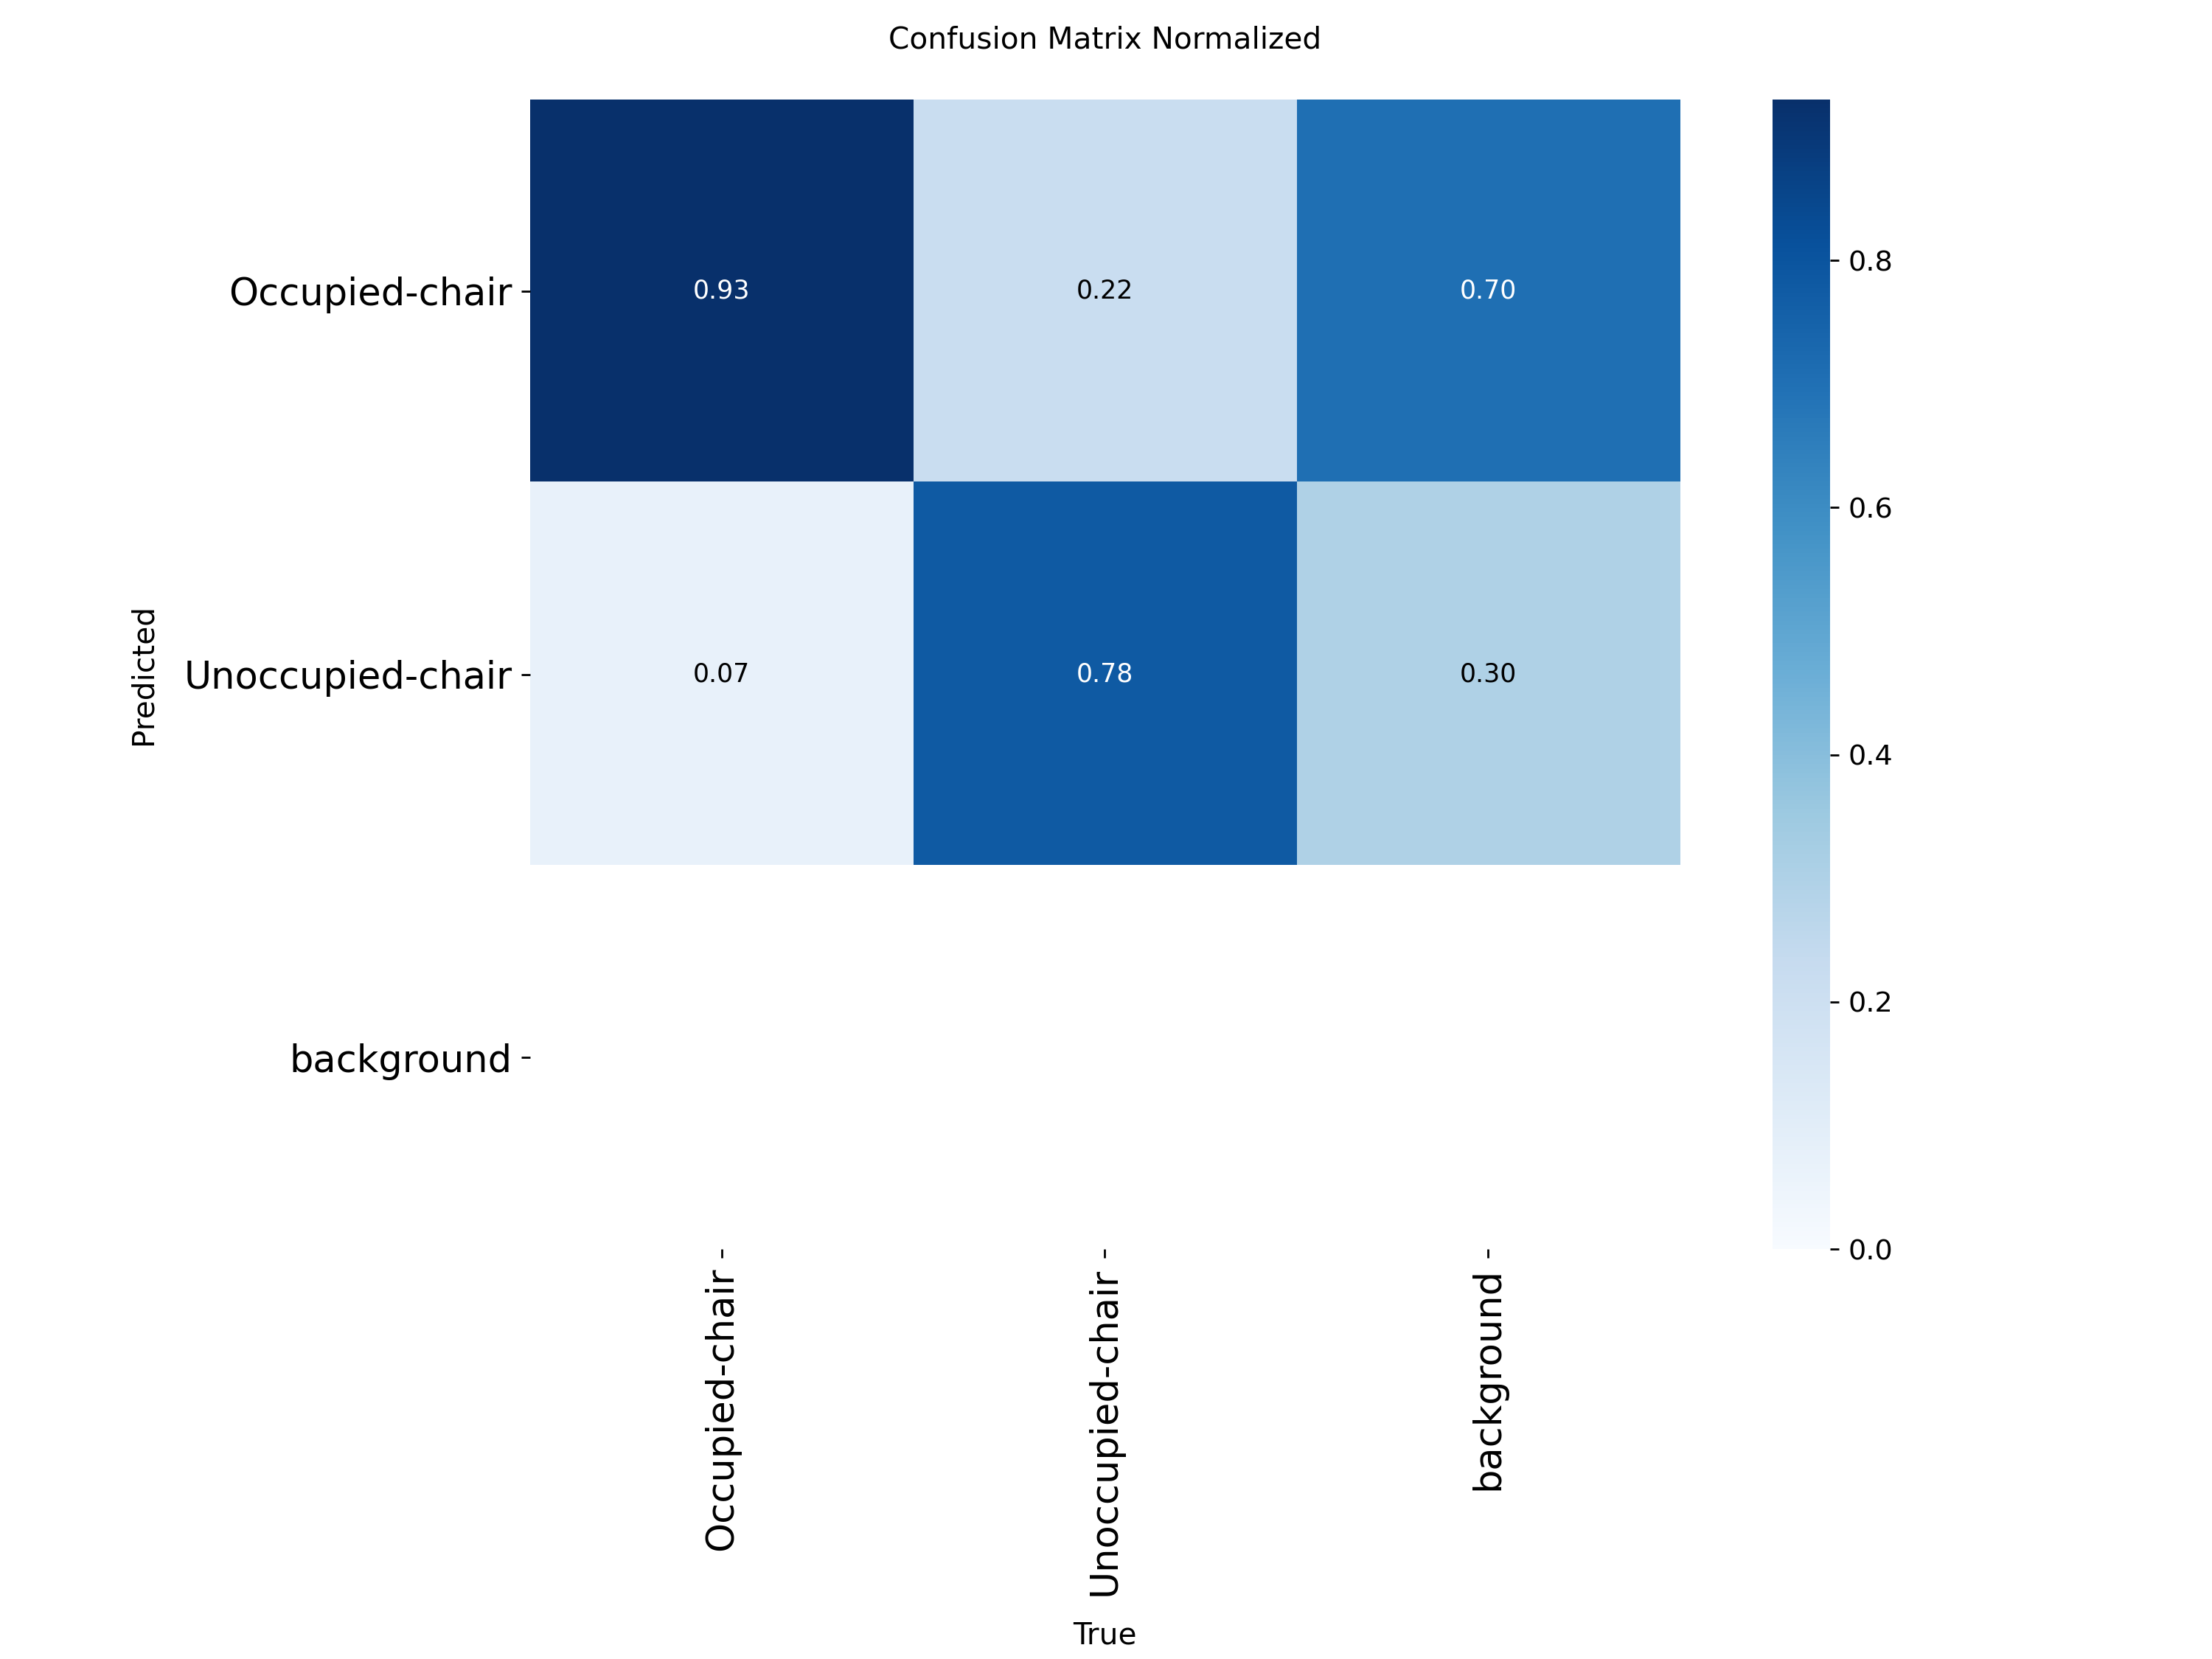

In [ ]:
cm_norm_path = "/content/runs/detect/val-2/confusion_matrix_normalized.png"

if os.path.exists(cm_norm_path):
    display(Image.open(cm_norm_path))
else:
    print("Normalized confusion matrix tidak ditemukan.")

Eksperimen Confidence Threshold

In [ ]:
import glob
import os
from collections import Counter

test_images = glob.glob("/content/chair_dataset_v2/test/images/*")

thresholds = [0.10, 0.25, 0.50, 0.75]

print(f"Jumlah gambar test: {len(test_images)}")
print()

for threshold in thresholds:

    total_objects = 0
    class_counts = Counter()
    confidence_scores = []

    for image_path in test_images:

        result = model.predict(
            source=image_path,
            conf=threshold,
            iou=0.45,
            verbose=False
        )[0]

        total_objects += len(result.boxes)

        for box in result.boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            class_counts[class_id] += 1
            confidence_scores.append(confidence)

    avg_conf = (
        sum(confidence_scores) / len(confidence_scores)
        if confidence_scores else 0
    )

    print(f"Confidence Threshold : {threshold:.2f}")
    print(f"Total deteksi        : {total_objects}")
    print(f"Occupied-chair       : {class_counts[0]}")
    print(f"Unoccupied-chair     : {class_counts[1]}")
    print(f"Rata-rata confidence : {avg_conf:.4f}")
    print("-" * 45)

Jumlah gambar test: 175

Confidence Threshold : 0.10
Total deteksi        : 1426
Occupied-chair       : 646
Unoccupied-chair     : 780
Rata-rata confidence : 0.8683
---------------------------------------------
Confidence Threshold : 0.25
Total deteksi        : 1413
Occupied-chair       : 642
Unoccupied-chair     : 771
Rata-rata confidence : 0.8749
---------------------------------------------
Confidence Threshold : 0.50
Total deteksi        : 1409
Occupied-chair       : 640
Unoccupied-chair     : 769
Rata-rata confidence : 0.8764
---------------------------------------------
Confidence Threshold : 0.75
Total deteksi        : 1346
Occupied-chair       : 583
Unoccupied-chair     : 763
Rata-rata confidence : 0.8850
---------------------------------------------


In [ ]:
import pandas as pd

results_threshold = []

for threshold in thresholds:

    total_objects = 0
    occupied = 0
    unoccupied = 0
    confidence_scores = []

    for image_path in test_images:

        result = model.predict(
            source=image_path,
            conf=threshold,
            iou=0.45,
            verbose=False
        )[0]

        total_objects += len(result.boxes)

        for box in result.boxes:
            class_id = int(box.cls[0])
            confidence = float(box.conf[0])

            confidence_scores.append(confidence)

            if class_id == 0:
                occupied += 1
            elif class_id == 1:
                unoccupied += 1

    results_threshold.append({
        "Confidence": threshold,
        "Total Deteksi": total_objects,
        "Occupied-chair": occupied,
        "Unoccupied-chair": unoccupied,
        "Rata-rata Confidence": round(
            sum(confidence_scores) / len(confidence_scores), 4
        )
    })

df_threshold = pd.DataFrame(results_threshold)

display(df_threshold)

,Confidence,Total Deteksi,Occupied-chair,Unoccupied-chair,Rata-rata Confidence
0,0.10,1426,646,780,0.8683
1,0.25,1413,642,771,0.8749
2,0.50,1409,640,769,0.8764
3,0.75,1346,583,763,0.8850


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'foto_kelasTest1.jpg', 'weights', 'yolov10n.pt', 'chair_dataset', 'runs', 'drive', '.ipynb_checkpoints', 'chair_dataset_v2', 'sample_data']


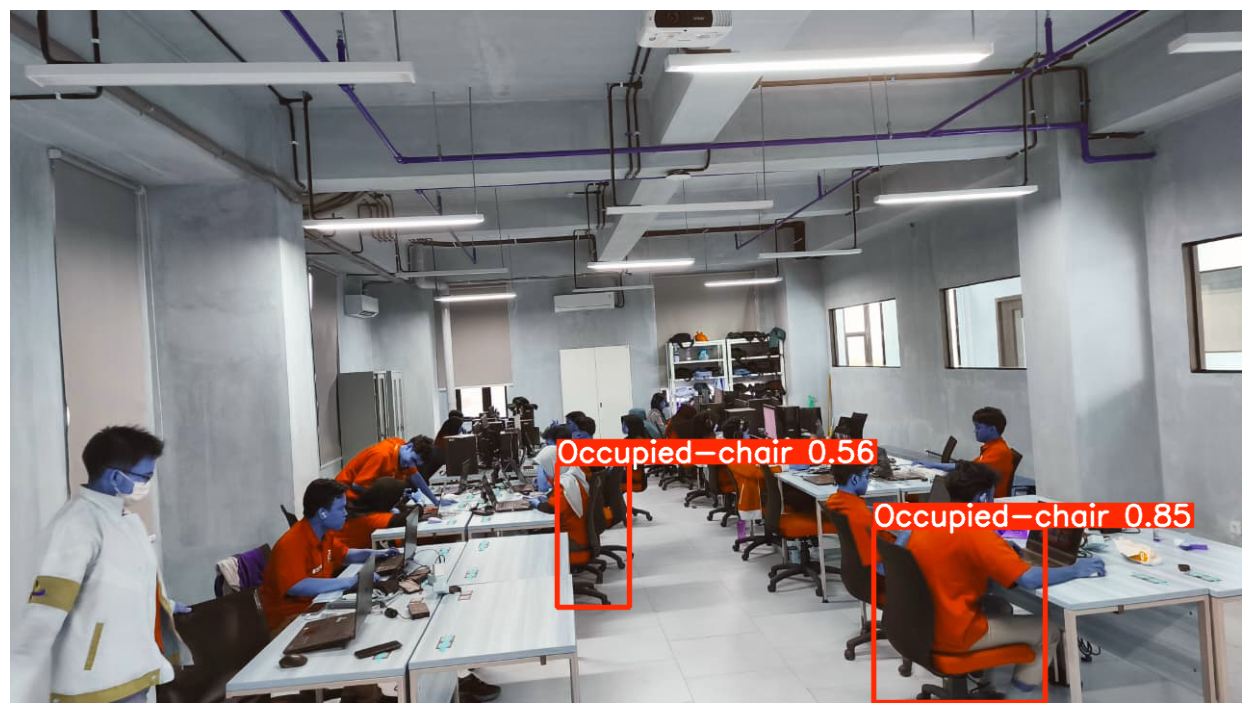

Jumlah objek terdeteksi: 2


In [ ]:
image_path = "/content/foto_kelasTest1.jpg"

result = model.predict(
    source=image_path,
    conf=0.50,
    iou=0.45,
    verbose=False
)[0]

import matplotlib.pyplot as plt

plt.figure(figsize=(16, 9))
plt.imshow(result.plot())
plt.axis("off")
plt.show()

print("Jumlah objek terdeteksi:", len(result.boxes))

Confidence 0.1: 19 objek


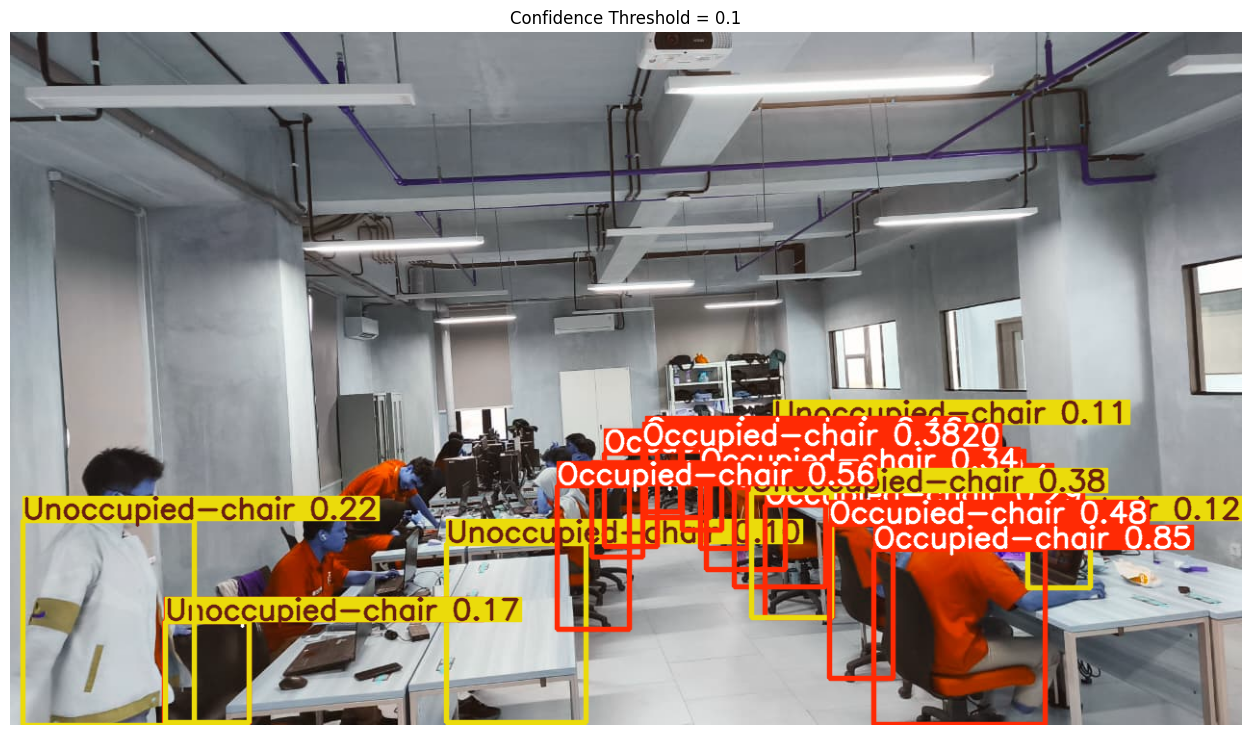

Confidence 0.25: 7 objek


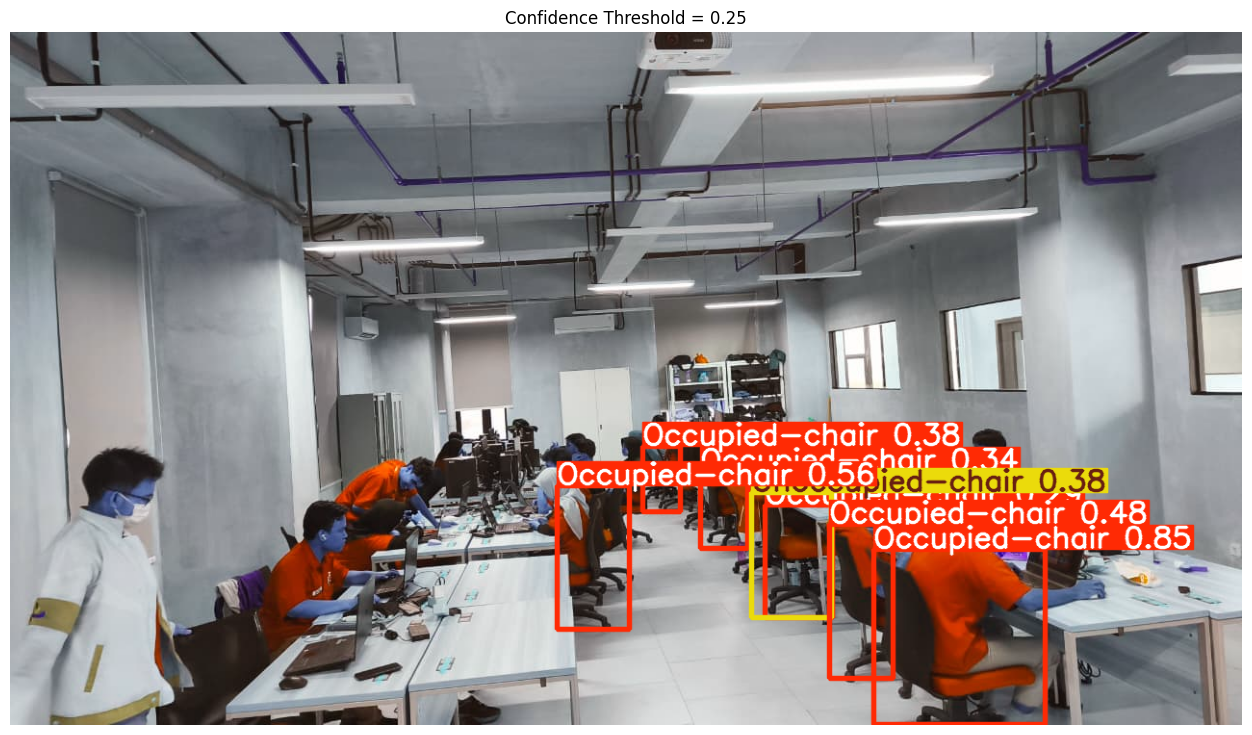

Confidence 0.5: 2 objek


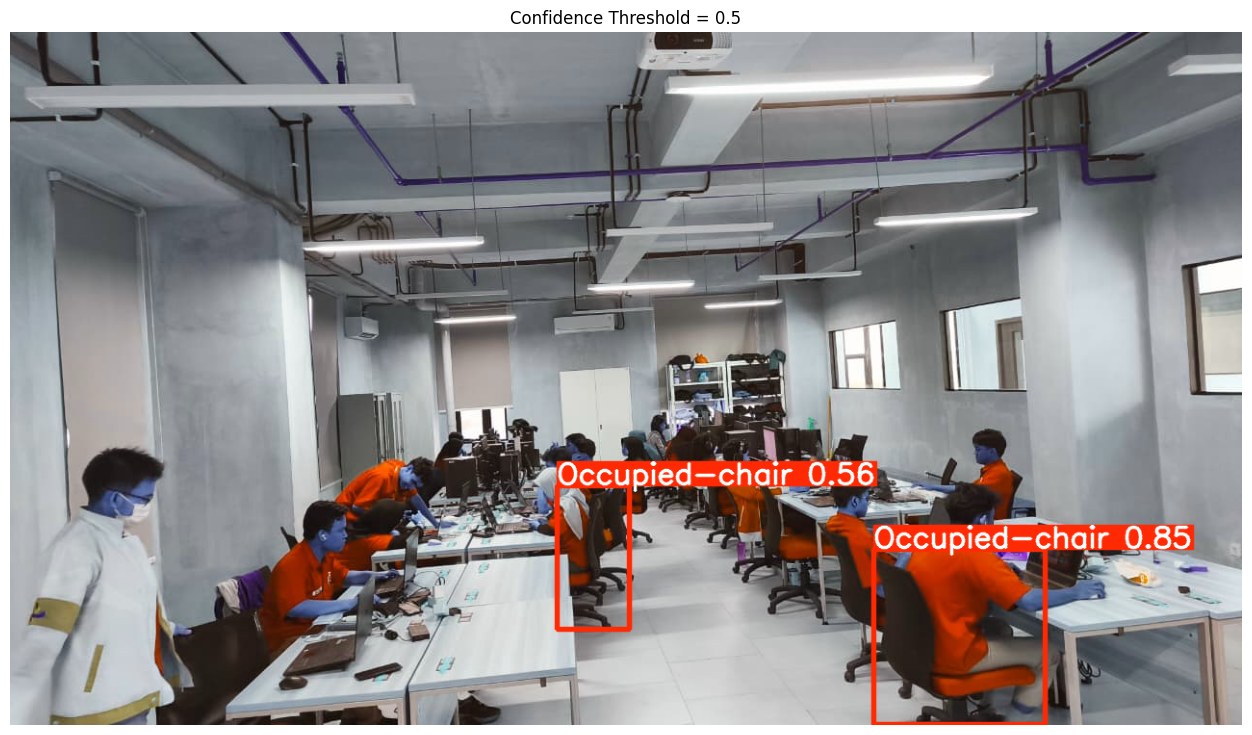

In [ ]:
import matplotlib.pyplot as plt

for conf in [0.10, 0.25, 0.50]:

    result = model.predict(
        source="/content/foto_kelasTest1.jpg",
        conf=conf,
        iou=0.45,
        verbose=False
    )[0]

    print(f"Confidence {conf}: {len(result.boxes)} objek")

    plt.figure(figsize=(16, 9))
    plt.imshow(result.plot())
    plt.title(f"Confidence Threshold = {conf}")
    plt.axis("off")
    plt.show()

In [ ]:
import glob

best_models = glob.glob("/content/runs/**/best.pt", recursive=True)

print("Jumlah best.pt:", len(best_models))

for model in best_models:
    print(model)

Jumlah best.pt: 1
/content/runs/yolov10n_chair-4/weights/best.pt


In [ ]:
from ultralytics import YOLO

model = YOLO("/content/runs/yolov10n_chair-4/weights/best.pt")

print(model.names)

{0: 'Occupied-chair', 1: 'Unoccupied-chair'}


In [44]:
from google.colab import files

files.download("/content/runs/yolov10n_chair-4/weights/best.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')